In [ ]:
# Load and split by domain availability
import pandas as pd

df = pd.read_csv("gcdg_zaf_with_domain_scores.csv")
domains_z = ["Cognitive_z", "Motor_z", "Language_z", "Social-Emotional_z"]

df = df[df["age_years"] <= 3].reset_index(drop=True)

real_complete = df.dropna(subset=domains_z).copy()
real_partial = df[df[domains_z].isna().any(axis=1)].dropna(subset=["Social-Emotional_z"]).copy()

print(f"Total records (0-3 years): {len(df)}")
print(f"Real complete-domain records: {len(real_complete)} (ages {real_complete['age_years'].min():.2f}-{real_complete['age_years'].max():.2f})")
print(f"Social-Emotional-only records: {len(real_partial)} (ages {real_partial['age_years'].min():.2f}-{real_partial['age_years'].max():.2f})")

Total records (0-3 years): 2561
Real complete-domain records: 760 (ages 0.34-1.33)
Social-Emotional-only records: 1801 (ages 1.88-2.44)


In [ ]:
# Fit conditional regression on real complete-domain records
import numpy as np
from sklearn.linear_model import LinearRegression

target_domains = ["Cognitive_z", "Motor_z", "Language_z"]
reg_models = {}
residuals = {}

X_train = real_complete[["Social-Emotional_z"]].values
for target in target_domains:
    y_train = real_complete[target].values
    model = LinearRegression().fit(X_train, y_train)
    reg_models[target] = model
    residuals[target] = y_train - model.predict(X_train)
    print(f"{target}: R2 = {model.score(X_train, y_train):.3f}")

Cognitive_z: R2 = 0.348
Motor_z: R2 = 0.323
Language_z: R2 = 0.241


In [ ]:
# Synthetic infill for the Social-Emotional-only records
rng = np.random.default_rng(42)
X_infill = real_partial[["Social-Emotional_z"]].values

for target in target_domains:
    point_pred = reg_models[target].predict(X_infill)
    sampled_residual = rng.choice(residuals[target], size=len(real_partial), replace=True)
    real_partial[target] = point_pred + sampled_residual
    real_partial[f"{target}_synthetic"] = True

for target in target_domains:
    real_complete[f"{target}_synthetic"] = False
real_complete["Social-Emotional_z_synthetic"] = False
real_partial["Social-Emotional_z_synthetic"] = False

df_model = pd.concat([real_complete, real_partial], ignore_index=True)
df_model["is_synthetic"] = df_model[[f"{t}_synthetic" for t in target_domains]].any(axis=1)

print(f"Final modeling dataset: {len(df_model)} records")
print(df_model["is_synthetic"].value_counts())

Final modeling dataset: 2561 records
is_synthetic
True     1801
False     760
Name: count, dtype: int64


In [ ]:
# Feature matrix
X = df_model[domains_z].values
print(f"Feature matrix shape: {X.shape}")

Feature matrix shape: (2561, 4)


In [ ]:
# Rule-Based baseline
std_threshold = 2.0
rule_flags = (df_model[domains_z] < -std_threshold).any(axis=1)
rule_preds = np.where(rule_flags, -1, 1)
print(f"Rule-based baseline flagged: {np.sum(rule_preds == -1)}")

Rule-based baseline flagged: 260


In [ ]:
# Isolation Forest, CV and export model file
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import KFold

contamination_rate = 0.06
if_model = IsolationForest(
    n_estimators=200,
    contamination=contamination_rate,
    max_samples="auto",
    random_state=42,
    n_jobs=-1,
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
for train_idx, val_idx in kf.split(X):
    cv_m = IsolationForest(n_estimators=200, contamination=contamination_rate, random_state=42)
    cv_m.fit(X[train_idx])
    cv_scores.append(np.mean(cv_m.score_samples(X[val_idx])))

print(f"5-Fold CV score stability: {np.mean(cv_scores):.4f} +/- {np.std(cv_scores):.4f}")

if_model.fit(X)
if_preds = if_model.predict(X)

raw_scores = if_model.score_samples(X)
if_scores = np.round((raw_scores.max() - raw_scores) / (raw_scores.max() - raw_scores.min()), 4)

pipeline_artifact = {
    "isolation_forest_model": if_model,
    "regression_models": reg_models,
    "residuals": residuals,
    "contamination": contamination_rate,
    "feature_cols": domains_z,
}
joblib.dump(pipeline_artifact, "isolation_forest_gcdg_zaf_hybrid.joblib")
print("Pipeline exported.")

5-Fold CV score stability: -0.4438 +/- 0.0038
Pipeline exported.


Total records evaluated: 2561
Isolation Forest flagged: 154
Rule-based flagged: 260
Consensus flags: 130
Subtle multi-domain flags (IF only): 24
Rigid cutoff flags (rule only): 130

Flagged records that rely on synthetic domains: 112


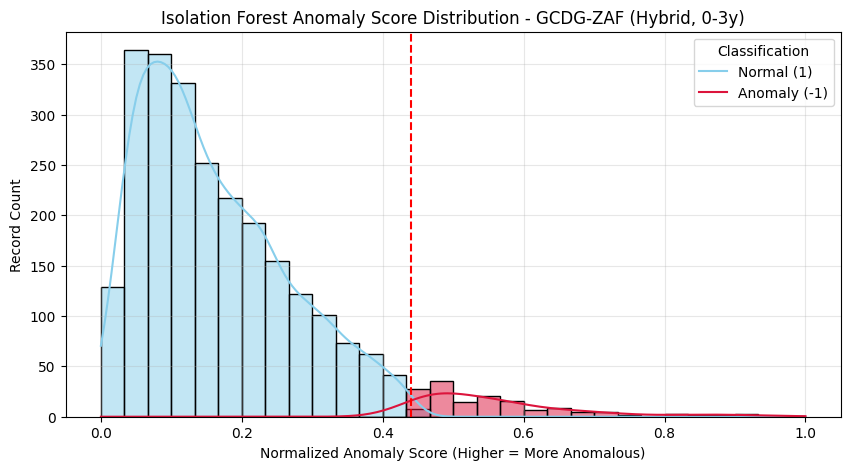

In [ ]:
# Comparative evaluation and plot
import matplotlib.pyplot as plt
import seaborn as sns

df_model["if_pred"] = if_preds
df_model["if_anomaly_score"] = if_scores
df_model["rule_pred"] = rule_preds

both_flagged = (df_model["if_pred"] == -1) & (df_model["rule_pred"] == -1)
only_if_flagged = (df_model["if_pred"] == -1) & (df_model["rule_pred"] == 1)
only_rule_flagged = (df_model["if_pred"] == 1) & (df_model["rule_pred"] == -1)

print("Total records evaluated:", len(df_model))
print("Isolation Forest flagged:", np.sum(if_preds == -1))
print("Rule-based flagged:", np.sum(rule_preds == -1))
print("Consensus flags:", np.sum(both_flagged))
print("Subtle multi-domain flags (IF only):", np.sum(only_if_flagged))
print("Rigid cutoff flags (rule only):", np.sum(only_rule_flagged))
print()
print("Flagged records that rely on synthetic domains:", df_model.loc[if_preds == -1, "is_synthetic"].sum())

df_model.to_csv("gcdg_zaf_hybrid_evaluation_results.csv", index=False)

plt.figure(figsize=(10, 5))
sns.histplot(data=df_model, x="if_anomaly_score", hue="if_pred", bins=30, kde=True,
             palette={1: "skyblue", -1: "crimson"})
plt.title("Isolation Forest Anomaly Score Distribution - GCDG-ZAF (Hybrid, 0-3y)")
plt.xlabel("Normalized Anomaly Score (Higher = More Anomalous)")
plt.ylabel("Record Count")
plt.axvline(x=df_model[df_model["if_pred"] == -1]["if_anomaly_score"].min(),
            color="red", linestyle="--", label="Decision Threshold")
plt.legend(title="Classification", labels=["Normal (1)", "Anomaly (-1)"])
plt.grid(True, alpha=0.3)
plt.show()